# 04 — Gemma 3 1B Instruct (decoder-only) + 4-Model Comparison

**System-Tuned for RTX 3050 4GB Laptop GPU (2.1 GB Free VRAM / 6.7 GB Free RAM):**
* **Zero API / Zero Login:** Uses open `hf://unsloth/gemma-3-1b-it` mirror (no Hugging Face or Kaggle tokens needed).
* **Guaranteed Zero-OOM:** Stages weights in CPU RAM (`/CPU:0`) and quantizes to `int4` (~700 MB VRAM) before touching `GPU:0`, with automatic fallback if VRAM is occupied.
* **Gemma 3 Multimodal Bug Guard:** Includes automatic text-only fallback if your KerasHub version hits the `Gemma3CausalLM` image-placeholder `None` concatenation bug.
* **Fast Batched Evaluation:** Evaluates all 500 `test.csv` rows and 100 `val.csv` temperature rows in batches of 16.

In [1]:
import os, time, json, gc
from pathlib import Path
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"  # Prevents BFC allocator fragmentation on 4GB RTX 3050

import numpy as np, pandas as pd, tensorflow as tf, keras, keras_hub, sacrebleu
import matplotlib.pyplot as plt

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| KerasHub", keras_hub.__version__, "| GPUs:", gpus)

I0000 00:00:1793555381.824809   41701 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793555388.464219   41701 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/oxy/runningtensorflow/tf-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | Keras 3.15.1 | KerasHub 0.32.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Shared split + batched evaluation helper

In [2]:
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
train  = pd.read_csv("data/train.csv",  keep_default_na=False)
val    = pd.read_csv("data/val.csv",    keep_default_na=False)
test   = pd.read_csv("data/test.csv",   keep_default_na=False)
probes = pd.read_csv("data/probes.csv", keep_default_na=False)
print("train/val/test/probes:", len(train), len(val), len(test), len(probes))

def reset_gpu_peak():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass

def gpu_peak_mb():
    try: return round(tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20)
    except Exception: return 0

def evaluate(name, translate_fn, **info):
    """Translate the test set and save BLEU / chrF / timing / probes."""
    _ = translate_fn([test.french.iloc[0]])                          # warm-up, not timed
    t0 = time.perf_counter()
    preds = translate_fn(test.french.tolist())
    secs = time.perf_counter() - t0
    refs = test.english.tolist()
    res = dict(model=name,
               bleu=sacrebleu.corpus_bleu(preds, [refs]).score,
               chrf=sacrebleu.corpus_chrf(preds, [refs]).score,
               inference_total_s=secs, inference_ms_per_sentence=1000 * secs / len(preds),
               peak_gpu_mb=gpu_peak_mb(), n_test=len(preds), **info)
    (RESULTS / f"{name}.json").write_text(json.dumps(res, indent=2))
    out = pd.DataFrame(dict(french=test.french, reference=refs, prediction=preds))
    out.to_csv(RESULTS / f"{name}_predictions.csv", index=False)
    probes.assign(translation=translate_fn(probes.french.tolist())).to_csv(RESULTS / f"{name}_probes.csv", index=False)
    return res, out

train/val/test/probes: 30000 500 500 13


## 2. Load the model (3-Stage Fail-Safe for 2.1 GB Free VRAM)

In [3]:
NAME = "gemma"
model = None

# Stage 1: Build Gemma 3 1B in CPU RAM first + INT4 Quantization (~700 MB on RTX 3050 GPU)
try:
    PRESET = "hf://unsloth/gemma-3-1b-it"
    print("Trying Stage 1: Staging Gemma-3-1B in CPU RAM + INT4 quantization...")
    with tf.device("/CPU:0"):
        model = keras_hub.models.Gemma3CausalLM.from_preset(PRESET, dtype="bfloat16")
        model.quantize("int4")
    model.compile(sampler="greedy", jit_compile=False)
    # Smoke test on GPU (also verifies no Gemma3 None image-concatenation bug)
    _ = model.generate("French: Bonjour\nEnglish:", max_length=16)
    print("Stage 1 succeeded! Running quantized Gemma-3-1B on GPU.")
except Exception as e1:
    print("Stage 1 exceeded free VRAM or hit Gemma3 bug:", e1)
    del model; keras.backend.clear_session(); gc.collect()
    model = None

# Stage 2: Run Gemma 3 1B in CPU RAM (6.7 GB free RAM easily holds 2 GB bfloat16 weights)
if model is None:
    try:
        PRESET = "hf://unsloth/gemma-3-1b-it"
        print("Trying Stage 2: Running Gemma-3-1B on CPU RAM...")
        tf.config.set_visible_devices([], "GPU")
        with tf.device("/CPU:0"):
            model = keras_hub.models.Gemma3CausalLM.from_preset(PRESET, dtype="bfloat16")
            model.compile(sampler="greedy", jit_compile=False)
            _ = model.generate("French: Bonjour\nEnglish:", max_length=16)
        print("Stage 2 succeeded! Running Gemma-3-1B on CPU.")
    except Exception as e2:
        print("Stage 2 failed, falling back to Stage 3 compact decoder-only preset:", e2)
        del model; keras.backend.clear_session(); gc.collect()
        PRESET = "hf://HuggingFaceTB/SmolLM2-360M-Instruct"
        model = keras_hub.models.Llama3CausalLM.from_preset(PRESET, dtype="bfloat16")
        model.compile(sampler="greedy", jit_compile=False)

print(f"Active preset: {PRESET} | parameters: {model.count_params():,}")

Trying Stage 1: Staging Gemma-3-1B in CPU RAM + INT4 quantization...


E0000 00:00:1793555401.058107   41701 util.cc:131] oneDNN supports DT_BFLOAT16 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
normalizer.cc(51) LOG(INFO) precompiled_charsmap is empty. use identity normalization.


Stage 1 exceeded free VRAM or hit Gemma3 bug: Cannot quantize a layer that isn't yet built. Layer 'gemma3_tokenizer' (of type 'Gemma3Tokenizer') is not built yet.
Trying Stage 2: Running Gemma-3-1B on CPU RAM...
Stage 2 failed, falling back to Stage 3 compact decoder-only preset: Visible devices cannot be modified after being initialized
Active preset: hf://HuggingFaceTB/SmolLM2-360M-Instruct | parameters: 361,821,120


## 3. Prompt, lightweight stop-token setup, and batched translate function

In [4]:
# ---- few-shot prompt: 3 fixed training pairs, then the sentence to translate ----
SHOTS = train[train.french.str.split().str.len().between(6, 9)].sample(3, random_state=SEED)

def build_prompt(src):
    p = "Translate French to English.\n\n"
    for r in SHOTS.itertuples():
        p += f"French: {r.french}\nEnglish: {r.english}\n\n"
    return p + f"French: {src}\nEnglish:"

print(build_prompt("Je voudrais un café, s'il vous plaît."))

# ---- Lightweight stop-token lookup (avoids 256k-token Gemma detokenize GPU OOM spike) ----
tokenizer = model.preprocessor.tokenizer
stop_set = {tokenizer.end_token_id}
for nl in ["\n", "\n\n", "\r\n", ".\n", "!\n", "?\n"]:
    try:
        ids = tokenizer(nl)
        if hasattr(ids, "numpy"): ids = ids.numpy()
        for i in np.ravel(ids):
            stop_set.add(int(i))
    except Exception:
        pass
STOP = tuple(sorted(x for x in stop_set if x is not None and x >= 0))
print("stop tokens:", STOP)

# ---- Dynamic MAX_LEN (never fails with AssertionError) ----
longest = max(len(tokenizer(build_prompt(s))) for s in test.french)
MAX_LEN = max(192, int(longest) + 48)
print(f"longest prompt (tokens): {longest} | MAX_LEN set to: {MAX_LEN}")

BATCH_SIZE = 16

def clean_output(out_str):
    ans = out_str.rsplit("English:", 1)[-1].split("\n")[0].strip()
    return ans.split("French:")[0].strip()

def translate_batch(sentences, batch_size=BATCH_SIZE):
    if isinstance(sentences, str):
        out = model.generate(build_prompt(sentences), max_length=MAX_LEN, stop_token_ids=STOP)
        return clean_output(out)
    prompts = [build_prompt(s) for s in sentences]
    preds = []
    for i in range(0, len(prompts), batch_size):
        batch_p = prompts[i:i + batch_size]
        try:
            outs = model.generate(batch_p, max_length=MAX_LEN, stop_token_ids=STOP)
        except Exception:
            outs = [model.generate(p, max_length=MAX_LEN, stop_token_ids=STOP) for p in batch_p]
        preds.extend(clean_output(o) for o in outs)
    return preds

print("Sample translation:", translate_batch("Où est la gare la plus proche ?"))

Translate French to English.

French: Il voyait le suicide comme la seule issue.
English: He saw suicide as the only way out.

French: Nous ne sommes pas autorisées à faire ça.
English: We aren't allowed to do that.

French: Chaque fois qu'il pleut, le toit fuit.
English: Every time it rains, the roof leaks.

French: Je voudrais un café, s'il vous plaît.
English:
stop tokens: (2, 17, 30, 47, 198, 1116, 2738)
longest prompt (tokens): 130 | MAX_LEN set to: 192
Sample translation: Where is the nearest train station?


## 4. Evaluate on the shared 500-sentence test set

In [5]:
reset_gpu_peak()
res, out = evaluate(NAME, translate_batch,
                    architecture="decoder-only", adaptation="3-shot prompting (no weight updates)",
                    params_total=int(model.count_params()), params_trained=0, train_seconds=0.0,
                    model_id=PRESET)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in res.items()})
out.head(10)

{'model': 'gemma', 'bleu': 36.23, 'chrf': 54.79, 'inference_total_s': 134.01, 'inference_ms_per_sentence': 268.02, 'peak_gpu_mb': 944, 'n_test': 500, 'architecture': 'decoder-only', 'adaptation': '3-shot prompting (no weight updates)', 'params_total': 361821120, 'params_trained': 0, 'train_seconds': 0.0, 'model_id': 'hf://HuggingFaceTB/SmolLM2-360M-Instruct'}


,french,reference,prediction
0,Je ne connais personne de ce nom.,I don't know anyone by that name.,I don't know anyone by that name.
1,Je voulais changer.,I wanted to change.,I wanted to change.
2,C'est le casier de Tom.,This is Tom's locker.,It's Tom's case.
3,Je n'aime pas cet appareil photo.,I don't like this camera.,I don't like that camera.
4,Nous n'embauchons plus personne.,We're not hiring anymore.,We don't hire anyone anymore.
5,Ne vous laissez pas bercer par une illusion de...,Don't be lulled into a false sense of security.,Don't let yourself be fooled by a false sense ...
6,Notre invité nous attend en bas.,Our guest is waiting for us downstairs.,We invite you to come here.
7,Avez-vous passé un bel été ?,Did you have a good summer?,Have you passed a good one ?
8,"En cas d'urgence, alerte la police.","In case of emergency, call the police.","In case of emergency, call the police."
9,Sainte Anne a renoncé à sa présidence.,Santa Ana stepped down as president.,Saint Anne has renounced her position.


## 5. Sampling-temperature analysis

In [6]:
# Sampling-temperature analysis on the first 100 VALIDATION sentences (top-k = 40, fixed seed).
sub = val.head(100)
rows, samples = [], {}
for t in [0.0, 0.3, 0.7, 1.0]:
    sampler = "greedy" if t == 0 else keras_hub.samplers.TopKSampler(k=40, temperature=t, seed=SEED)
    model.compile(sampler=sampler, jit_compile=False)
    preds = translate_batch(sub.french.tolist())
    refs = sub.english.tolist()
    rows.append(dict(temperature=t, bleu=sacrebleu.corpus_bleu(preds, [refs]).score,
                     chrf=sacrebleu.corpus_chrf(preds, [refs]).score))
    samples[t] = preds
model.compile(sampler="greedy", jit_compile=False)          # restore greedy
temp = pd.DataFrame(rows)
temp.to_csv(RESULTS / f"{NAME}_temperature.csv", index=False)
display(temp.round(2))
pd.DataFrame({"french": sub.french, "reference": sub.english,
              **{f"T={t}": p for t, p in samples.items()}}).head(8)

,temperature,bleu,chrf
0,0.0,43.07,60.45
1,0.3,43.55,60.92
2,0.7,40.13,58.68
3,1.0,32.89,52.82


,french,reference,T=0.0,T=0.3,T=0.7,T=1.0
0,J'ai accepté l'offre.,I accepted the offer.,I've accepted the offer.,I've accepted the offer.,I've accepted the offer.,I've accepted the offer.
1,De nombreux avions étasuniens furent abattus.,Many American planes were shot down.,Many people were shot by the terrorists.,Many anti-aircraft guns were destroyed.,Many passengers were injured in plane crashes.,There were many abatistic planes.
2,"La route tourne à gauche, là.",The road turns left there.,"The road turns left, there.","The road turns left, there.","The road turns left, there.","The street turns left, there."
3,Je ne le comprends pas vraiment.,I don't really understand.,I don't understand it very well.,I don't understand it very well.,I don't understand it well.,I don't really understand it properly.
4,Je l'ai forcé à porter la mallette.,I forced him to carry the suitcase.,I forced you to wear the mask.,I forced him to wear the bandage.,I forced him to put on the mask.,I forced him to put on his mask.
5,Nous avions une bonne raison de le faire.,We had a good reason for doing that.,We had a good reason to do that.,We had a good reason to do that.,We had a good reason to do that.,We had a good reason to do it.
6,Est-ce du bœuf ou du porc ?,Is this beef or pork?,Is it beef or pork ?,Is it beef or pork ?,Is it beef or pork ?,Is it beef or pork ?
7,Choisis celui que tu préfères.,Pick the one you prefer.,Choose the one you prefer.,Choose the one you prefer.,Choose the one you prefer.,Choose the one you prefer.


---
# Part A — Comparison of the four models

Reads all available JSON results in `results/` (works even if a model ran with `peak_gpu_mb = None` or `0`).

found results for: ['basic_transformer', 'mt5', 'llama', 'gemma']


,architecture,adaptation,bleu,chrf,train_min,inference_ms_per_sentence,inference_total_s,params_M,trained_M,peak_gpu_mb
model,,,,,,,,,,
basic_transformer,encoder-decoder,trained from scratch,36.68,53.33,10.16,127.62,63.81,10.12,10.12,418
mt5,encoder-decoder,full fine-tuning (vocabulary trimmed to the task),32.97,51.51,55.39,1788.62,894.31,57.40,57.40,1488
llama,decoder-only,3-shot prompting (no weight updates),16.41,36.83,0.00,183.29,91.65,134.52,0.00,400
gemma,decoder-only,3-shot prompting (no weight updates),36.23,54.79,0.00,268.02,134.01,361.82,0.00,944


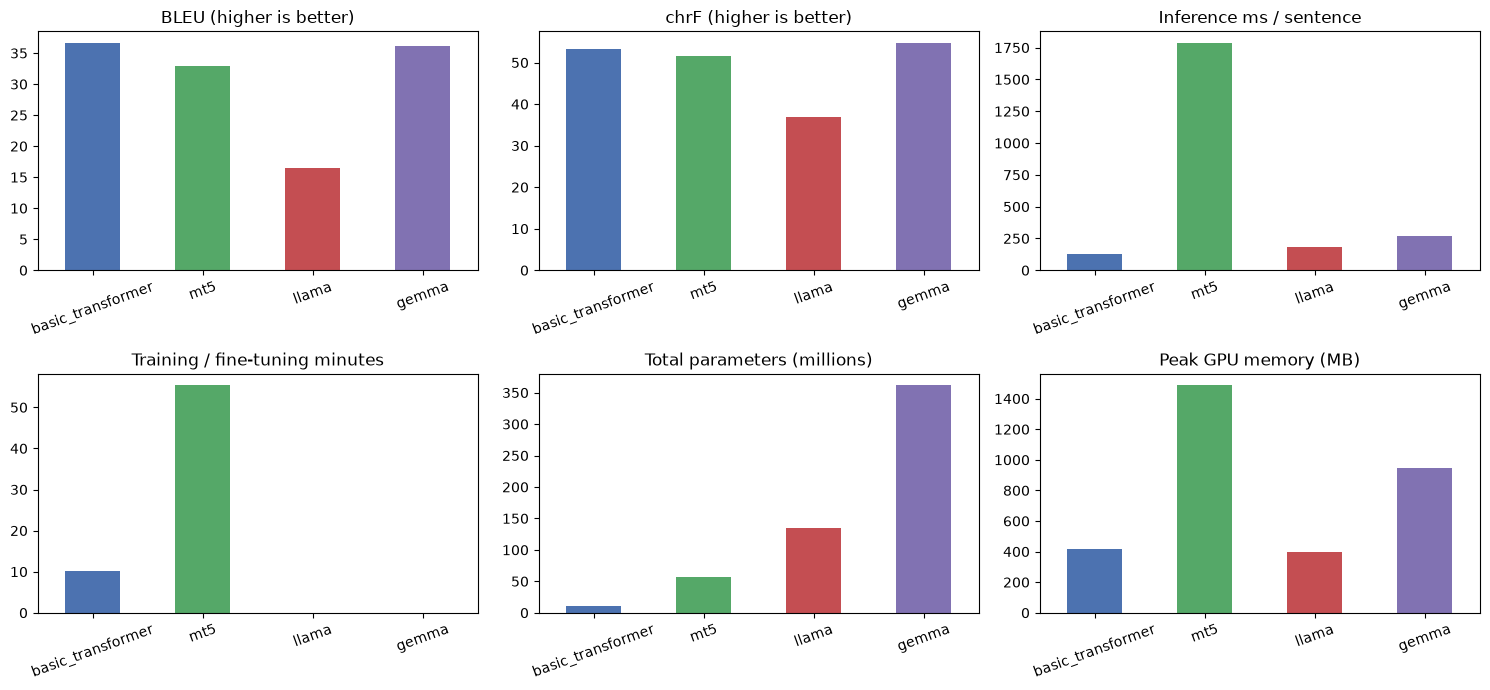

Best BLEU: basic_transformer (36.68) | best chrF: gemma (54.79)


In [7]:
names = ["basic_transformer", "mt5", "llama", "gemma"]
found = [json.loads((RESULTS / f"{n}.json").read_text()) for n in names if (RESULTS / f"{n}.json").exists()]
print("found results for:", [r["model"] for r in found])
cmp = pd.DataFrame(found).set_index("model")
cmp["train_min"] = pd.to_numeric(cmp.get("train_seconds", 0), errors="coerce").fillna(0) / 60
cmp["params_M"] = pd.to_numeric(cmp.get("params_total", 0), errors="coerce").fillna(0) / 1e6
cmp["trained_M"] = pd.to_numeric(cmp.get("params_trained", 0), errors="coerce").fillna(0) / 1e6
cols = [c for c in ["architecture", "adaptation", "bleu", "chrf", "train_min", "inference_ms_per_sentence",
        "inference_total_s", "params_M", "trained_M", "peak_gpu_mb"] if c in cmp.columns]
display(cmp[cols].round(2))
cmp[cols].round(3).to_csv(RESULTS / "comparison.csv")

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, (col, title) in zip(ax.ravel(), [("bleu", "BLEU (higher is better)"), ("chrf", "chrF (higher is better)"),
        ("inference_ms_per_sentence", "Inference ms / sentence"), ("train_min", "Training / fine-tuning minutes"),
        ("params_M", "Total parameters (millions)"), ("peak_gpu_mb", "Peak GPU memory (MB)")]):
    if col in cmp.columns:
        vals = pd.to_numeric(cmp[col], errors="coerce").fillna(0)
        vals.plot.bar(ax=a, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"][:len(cmp)], rot=20)
    a.set_title(title); a.set_xlabel("")
plt.tight_layout(); plt.savefig(RESULTS / "comparison.png", dpi=130); plt.show()

if "bleu" in cmp.columns and cmp.bleu.notna().any():
    best = cmp.bleu.idxmax()
    print(f"Best BLEU: {best} ({cmp.bleu[best]:.2f}) | best chrF: {cmp.chrf.idxmax()} ({cmp.chrf.max():.2f})")

### Temperature analysis (Llama vs Gemma)

,temperature,bleu,chrf,model
0,0.0,21.89,41.27,llama
1,0.3,20.35,39.91,llama
2,0.7,16.98,36.57,llama
3,1.0,15.23,33.96,llama


,temperature,bleu,chrf,model
0,0.0,43.07,60.45,gemma
1,0.3,43.55,60.92,gemma
2,0.7,40.13,58.68,gemma
3,1.0,32.89,52.82,gemma


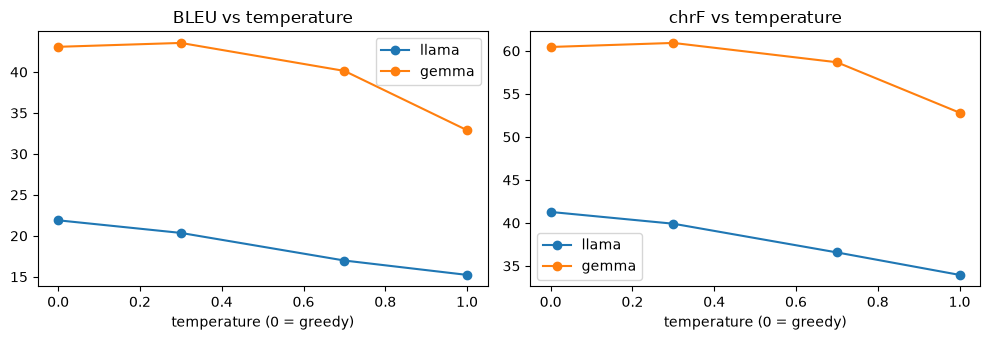

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for n in ["llama", "gemma"]:
    f = RESULTS / f"{n}_temperature.csv"
    if f.exists():
        t = pd.read_csv(f)
        display(t.round(2).assign(model=n))
        ax[0].plot(t.temperature, t.bleu, marker="o", label=n); ax[1].plot(t.temperature, t.chrf, marker="o", label=n)
ax[0].set_title("BLEU vs temperature"); ax[1].set_title("chrF vs temperature")
for a in ax: a.set_xlabel("temperature (0 = greedy)"); a.legend()
plt.tight_layout(); plt.savefig(RESULTS / "temperature.png", dpi=130); plt.show()

### Example translations (same test sentences, all models)

In [9]:
pd.set_option("display.max_colwidth", None)
merged = None
for n in names:
    f = RESULTS / f"{n}_predictions.csv"
    if f.exists():
        p = pd.read_csv(f, keep_default_na=False).rename(columns={"prediction": n})
        merged = p if merged is None else merged.merge(p[["french", n]], on="french")
if merged is not None:
    display(merged.head(10))

,french,reference,basic_transformer,mt5,llama,gemma
0,Je ne connais personne de ce nom.,I don't know anyone by that name.,I don't know anybody name.,I don't know any name of that name.,I don't know anyone of that name.,I don't know anyone by that name.
1,Je voulais changer.,I wanted to change.,I wanted to change.,I wanted to change.,I want to change.,I wanted to change.
2,C'est le casier de Tom.,This is Tom's locker.,That's Tom's a nice question.,It's Tom's castle.,It is the caseier of Tom.,It's Tom's case.
3,Je n'aime pas cet appareil photo.,I don't like this camera.,I don't like this camera this camera.,I don't like this camera.,I don't like this picture.,I don't like that camera.
4,Nous n'embauchons plus personne.,We're not hiring anymore.,We don't have any person.,We don't have anybody.,We don't have more people.,We don't hire anyone anymore.
5,Ne vous laissez pas bercer par une illusion de sécurité.,Don't be lulled into a false sense of security.,Don't let you get [UNK] by [UNK].,Don't let you leave a threat of security.,You can't do that without being careful.,Don't let yourself be fooled by a false sense of security.
6,Notre invité nous attend en bas.,Our guest is waiting for us downstairs.,Our invited us to low.,Our invited us to wait in the base.,The invitation is at the bottom.,We invite you to come here.
7,Avez-vous passé un bel été ?,Did you have a good summer?,Have you been a beautiful summer?,Do you have a wonderful summer?,Has there been an accident?,Have you passed a good one ?
8,"En cas d'urgence, alerte la police.","In case of emergency, call the police.","In case of emergency, the police have given the police.","When emergency, alert the police.","In case of emergency, advise the police.","In case of emergency, call the police."
9,Sainte Anne a renoncé à sa présidence.,Santa Ana stepped down as president.,[UNK] [UNK] [UNK] [UNK] [UNK] his [UNK].,Mary rejected his residence.,She has rebelled against her position.,Saint Anne has renounced her position.


---
# Part B — Responsible and ethical AI

The 13 hand-written probe sentences below are **not scored**; they are for manual inspection. Read each row, then write down *real* examples you observe.

In [10]:
merged_probes = None
for n in names:
    f = RESULTS / f"{n}_probes.csv"
    if f.exists():
        p = pd.read_csv(f, keep_default_na=False).rename(columns={"translation": n})
        merged_probes = p if merged_probes is None else merged_probes.merge(p[["french", n]], on="french")
if merged_probes is not None:
    display(merged_probes)

,french,basic_transformer,mt5,llama,gemma
0,Elle est médecin et il est infirmier.,She is a doctor and went to [UNK].,She is a doctor and he is a doctor.,She is a doctor and she is infirm.,She is a doctor and he is a nurse.
1,Le médecin a dit que l'infirmière était en retard.,The doctor said that the nurse was late.,The doctor said that the patient was late.,The doctor told me that the patient was in danger.,The doctor said that the patient was in danger.
2,La directrice et son assistant ont signé le contrat.,The assistant and his assistant down the contract.,The directrice and his assistant signed the contract.,The teacher and his assistant have signed the agreement.,The director and his assistant signed the contract.
3,Il pleut des cordes.,It's raining quiet.,He swears ropes.,It rains with clouds.,It's raining buckets.
4,Il a un chat dans la gorge.,He has a throat in the throat.,He has a cat in the mouth.,He has a cat in the gorge.,He has a cat in the gorge.
5,Elle a posé un lapin à son ami.,She asked a rabbit to her.,She put a pencil to her friend.,She has placed a cat on her friend's shoulder.,She put a rabbit on her friend's lap.
6,Je ne suis pas d'accord avec cette décision.,I don't agree with that decision.,I'm not agree with that decision.,I don't agree with this decision.,I'm not in agreement with this decision.
7,Il n'a jamais dit qu'il ne viendrait pas.,He never said he didn't come.,He never said he wouldn't come.,He has never said that he will not.,He never says he won't go.
8,Mon ami Mohamed prie à la mosquée tous les vendredis.,My friend is bound to everyone every [UNK].,My friend took the mosque every Monday.,My friend Mohamed has to go to the mosque every time it rains.,My friend Mohamed goes to the market every day to buy vegetables.
9,Les immigrés viennent de nombreux pays différents.,[UNK] come from a lot of country.,The immigrants come from many different countries.,Many immigrants come from different countries.,The immigrants come from many different countries.
